In [90]:
import numpy as np
import matplotlib.pyplot as plt
import time
from numpy.random import seed, rand
import sys
import os
import pandas as pd 
from IPython.display import Image, display
import matplotlib.animation as animation
import subprocess
from typing import Tuple, List, Optional, Dict, Any

In [69]:
def importar_ant_colony_optimizer(
    repo_url: str = "https://github.com/johnberroa/Ant-Colony-Optimization.git",
    nombre_carpeta: str = "Ant-Colony-Optimization"
):
    """
    Clona el repositorio de Ant Colony Optimization si no existe localmente,
    lo agrega a la ruta del interpretador (sys.path) e importa la clase AntColonyOptimizer.

    Parámetros:
    -----------
    repo_url : str, opcional
        URL del repositorio de GitHub a clonar.
    nombre_carpeta : str, opcional
        Nombre de la carpeta del repositorio local.

    Retorna:
    --------
    class
        La clase AntColonyOptimizer importada y lista para instanciar.
    """
    # 1. Determinar posibles ubicaciones de la carpeta
    ruta_repo = os.path.abspath(nombre_carpeta)

    # 2. Si no existe localmente, clonar el repositorio con Git
    if ruta_repo is None:
        print(f"Clonando repositorio desde: {repo_url} ...")
        try:
            subprocess.run(["git", "clone", repo_url], check=True)
            ruta_repo = os.path.abspath(nombre_carpeta)
            print("Repositorio clonado exitosamente.")
        except Exception as e:
            raise RuntimeError(f"Error al clonar el repositorio con Git: {e}")
    else:
        print(f"Repositorio encontrado localmente en: {ruta_repo}")

    # 3. Agregar la carpeta a sys.path si no está incluida
    if ruta_repo not in sys.path:
        sys.path.append(ruta_repo)

    # 4. Importar dinámicamente la clase
    try:
        from AntColonyOptimizer import AntColonyOptimizer
        print("Clase 'AntColonyOptimizer' cargada exitosamente.")
        return AntColonyOptimizer
    except ImportError as e:
        raise ImportError(f"No se pudo importar AntColonyOptimizer desde {ruta_repo}: {e}")


In [83]:
def cargar_matriz_costos_viajero(
    nombre_archivo: str = "matriz_costo_total_euros.csv",
    carpeta: str = "Resultados_CSV_ANT"
) -> Tuple[pd.DataFrame, List[str], np.ndarray]:
    """
    Localiza y carga la matriz de costo económico total del TSP desde la carpeta 
    Resultados_CSV_ANT, asegurando indexación correcta y formato NumPy listo para ACO.

    Parámetros:
    -----------
    nombre_archivo : str, opcional
        Nombre del archivo CSV (por defecto 'matriz_costo_total_euros.csv').
    carpeta : str, opcional
        Nombre de la subcarpeta donde se almacenan los CSVs (por defecto 'Resultados_CSV_ANT').

    Retorna:
    --------
    Tuple[pd.DataFrame, List[str], np.ndarray]
        - df_costos: DataFrame de Pandas con índices y nombres de columnas.
        - ciudades: Lista con los nombres de las 47 ciudades.
        - matriz_costos: Matriz NumPy pura (N x N) de tipo float.
    """
    ruta_encontrada = os.path.join(carpeta, nombre_archivo)

    if ruta_encontrada is None:
        raise FileNotFoundError(
            f"No se encontró el archivo '{nombre_archivo}'. "
            f"Verifica que esté en '{carpeta}/' o 'Parte_2/{carpeta}/'."
        )

    # 1. Cargar CSV asegurando la primera columna como índice (ciudades)
    df_costos = pd.read_csv(ruta_encontrada, index_col=0, encoding="utf-8-sig")
    
    # 2. Extraer lista de nombres
    ciudades = list(df_costos.index)

    # 3. Extraer matriz NumPy de floats (47 x 47)
    matriz_costos = df_costos.values.astype(float)

    # 4. Validar que la matriz sea estrictamente cuadrada
    assert matriz_costos.shape[0] == matriz_costos.shape[1], (
        f"Error de dimensiones: La matriz no es cuadrada ({matriz_costos.shape})"
    )

    print(f"Dimensiones de la matriz: {matriz_costos.shape}")
    print(f"Total de ciudades: {len(ciudades)}")

    return df_costos, ciudades, matriz_costos


In [81]:
# Cargar la información con una sola línea
df_costos, ciudades, matriz_costos = cargar_matriz_costos_viajero()

# Visualizar las primeras filas del DataFrame en Jupyter
df_costos.head()


Dimensiones de la matriz: (47, 47)
Total de ciudades: 47


,A Coruña,Albacete,Alicante,Almería,Ávila,Badajoz,Barcelona,Bilbao,Burgos,Cáceres,...,Sevilla,Soria,Tarragona,Teruel,Toledo,Valencia,Valladolid,Vitoria-Gasteiz,Zamora,Zaragoza
A Coruña,0.00,153.58,182.46,205.10,94.23,123.60,196.04,99.54,87.52,118.87,...,164.58,117.86,181.99,167.94,118.72,171.74,78.41,108.47,74.45,142.89
Albacete,153.26,0.00,30.95,61.32,68.11,99.22,95.10,116.46,88.42,93.48,...,90.94,84.90,77.48,58.26,47.03,33.27,83.10,109.48,104.33,78.78
Alicante,182.05,30.88,0.00,50.79,96.90,128.01,97.59,141.39,117.21,122.27,...,111.13,113.69,79.96,70.38,75.81,32.84,111.88,134.51,133.12,90.89
Almería,207.24,60.22,49.58,0.00,119.63,117.15,137.88,174.58,146.54,124.20,...,77.96,143.03,120.25,110.76,93.01,73.13,137.07,167.60,158.30,131.27
Ávila,93.90,67.94,96.82,119.47,0.00,66.39,132.75,76.72,48.79,48.37,...,94.08,51.08,118.70,85.84,28.71,86.10,24.03,69.74,45.07,79.60


In [88]:
def mostrar_scatter_ciudades_tsp(
    df_coords: Optional[pd.DataFrame] = None,
    nombre_archivo: str = "coordenadas_capitales_espana.csv",
    carpeta: str = "Resultados_CSV_ANT",
    figsize: tuple = (12, 8)
) -> pd.DataFrame:
    """
    Carga las coordenadas de las capitales provinciales y muestra en pantalla 
    un scatter plot con la distribución geográfica real de los nodos del TSP,
    sin guardar archivos en disco.

    Parámetros:
    -----------
    df_coords : Optional[pd.DataFrame], opcional
        DataFrame con columnas ['ciudad', 'latitud', 'longitud']. Si es None,
        se busca y carga automáticamente el archivo CSV.
    nombre_archivo : str, opcional
        Nombre del archivo CSV de coordenadas (por defecto 'coordenadas_capitales_espana.csv').
    carpeta : str, opcional
        Carpeta donde reside el CSV (por defecto 'Resultados_CSV_ANT').
    figsize : tuple, opcional
        Dimensiones de la figura de Matplotlib en pulgadas (por defecto (12, 8)).

    Retorna:
    --------
    pd.DataFrame
        DataFrame de coordenadas utilizado para el gráfico.
    """   
    ruta_encontrada = os.path.join(carpeta, nombre_archivo)

                
    if ruta_encontrada is None:
            raise FileNotFoundError(
                f"No se encontró el archivo '{nombre_archivo}' en '{carpeta}/' ni en la raíz."
            )
            
    df_coords = pd.read_csv(ruta_encontrada, encoding="utf-8-sig")

    # 2. Configurar la figura del Scatter Plot
    plt.figure(figsize=figsize)

    # 3. Graficar los puntos (Longitud en X, Latitud en Y)
    plt.scatter(
        df_coords["longitud"], 
        df_coords["latitud"], 
        color="#1f77b4", 
        s=95, 
        edgecolors="black", 
        linewidth=1.2, 
        zorder=3
    )

    # 4. Etiquetar cada capital con su índice numérico y nombre
    for i, row in df_coords.iterrows():
        plt.annotate(
            f"{i}. {row['ciudad']}",
            (row["longitud"], row["latitud"]),
            textcoords="offset points",
            xytext=(5, 4),
            fontsize=8,
            fontweight="semibold",
            alpha=0.85
        )

    # 5. Formato y proporciones cartográficas reales
    plt.title("Ubicación Geográfica de las 47 Capitales Provinciales (Nodos TSP)", fontsize=13, pad=15)
    plt.xlabel("Longitud (°)", fontsize=11)
    plt.ylabel("Latitud (°)", fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.axis("equal")  # Evita la distorsión geográfica de la península ibérica
    plt.tight_layout()
    
    # 6. Mostrar exclusivamente en pantalla (sin guardar)
    plt.show()

    return df_coords


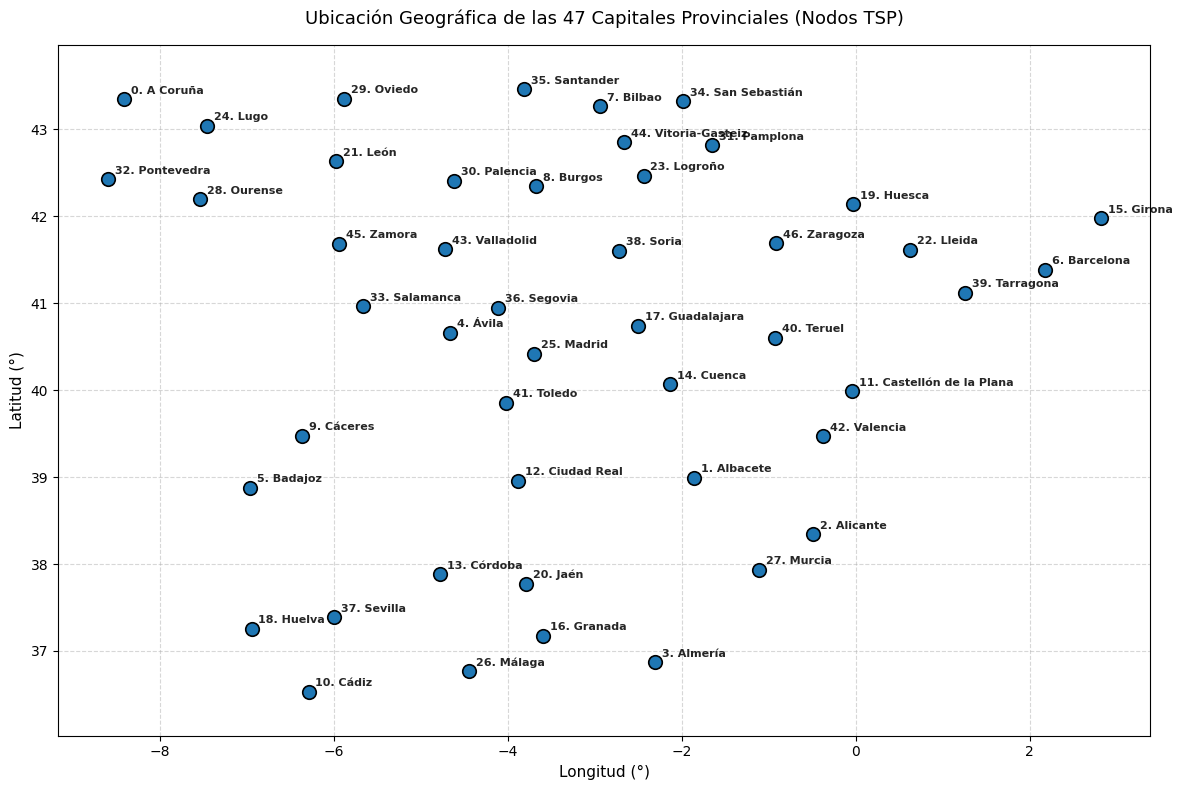

In [89]:
# Carga las coordenadas desde Resultados_CSV_ANT y muestra el scatter plot
df_coords = mostrar_scatter_ciudades_tsp()


In [119]:
def comparar_escenarios_aco(
    matriz_costos: np.ndarray,
    iteraciones: int = 200,
    carpeta_salida: str = "Resultados imagenes",
    nombre_archivo: str = "comparacion_hiperparametros_aco.png",
    semilla: int = 42
) -> Dict[str, Any]:
    """
    Ejecuta y compara tres configuraciones de hiperparámetros de ACO (Base, 
    Explorador y Voraz) sobre la matriz de costos, genera la curva de convergencia
    comparativa y exporta el gráfico a la carpeta de imágenes.

    Parámetros:
    -----------
    matriz_costos : np.ndarray
        Matriz simétrica (N x N) con los costos en euros del TSP.
    iteraciones : int, opcional
        Número de iteraciones por simulación (por defecto 200).
    carpeta_salida : str, opcional
        Carpeta donde se guardará la imagen (por defecto 'Resultados imagenes').
    nombre_archivo : str, opcional
        Nombre del archivo de imagen a generar (por defecto 'comparacion_hiperparametros_aco.png').
    semilla : int, opcional
        Semilla aleatoria para garantizar reproducibilidad justa (por defecto 42).

    Retorna:
    --------
    Dict[str, Any]
        Diccionario con los tres optimizadores entrenados y sus respectivos mejores costos.
    """
    # 1. Asegurar la importación de la clase AntColonyOptimizer
    AntColonyOptimizer = importar_ant_colony_optimizer()

    print(f"Iniciando comparación de 3 escenarios ACO ({iteraciones} iteraciones c/u)...")
    print("-" * 65)


    # Escenario 1: Configuración Base (Equilibrada)

    np.random.seed(semilla)
    t0 = time.time()
    print("[1/3] Ejecutando Escenario Base (ants=30, α=1.0, β=2.0, ρ=0.10)...")
    opt_base = AntColonyOptimizer(
        ants=30, 
        evaporation_rate=0.10, 
        intensification=2.0, 
        alpha=1.0, 
        beta=2.0, 
        choose_best=0.10
    )
    opt_base.fit(matriz_costos, iterations=iteraciones, verbose=False)
    tiempo_base = time.time() - t0
    print(f" Base finalizado: {opt_base.best:.2f} € en {tiempo_base:.1f}s")


    # Escenario 2: Configuración Exploradora (Más hormigas, baja evaporación)

    np.random.seed(semilla)
    t0 = time.time()
    print("[2/3] Ejecutando Escenario Explorador (ants=50, α=1.0, β=2.5, ρ=0.05)...")
    opt_explorador = AntColonyOptimizer(
        ants=50, 
        evaporation_rate=0.05, 
        intensification=1.5, 
        alpha=1.0, 
        beta=2.5, 
        choose_best=0.05  # 100% ruleta probabilística
    )
    opt_explorador.fit(matriz_costos, iterations=iteraciones, verbose=False)
    tiempo_explorador = time.time() - t0
    print(f"Explorador finalizado: {opt_explorador.best:.2f} € en {tiempo_explorador:.1f}s")

   
    # Escenario 3: Configuración Voraz (Heurística agresiva y alta explotación)
    np.random.seed(semilla)
    t0 = time.time()
    print("[3/3] Ejecutando Escenario Voraz (ants=20, α=1.5, β=4.5, ρ=0.20)...")
    opt_voraz = AntColonyOptimizer(
        ants=20, 
        evaporation_rate=0.20, 
        intensification=3.0, 
        alpha=1.5, 
        beta=4.5, 
        choose_best=0.25  # 25% elección determinista voraz
    )
    opt_voraz.fit(matriz_costos, iterations=iteraciones, verbose=False)
    tiempo_voraz = time.time() - t0
    print(f"Voraz finalizado: {opt_voraz.best:.2f} € en {tiempo_voraz:.1f}s")
    print("-" * 65)

    
    # Graficar y Exportar la Comparación
    plt.figure(figsize=(13, 7))

    plt.plot(
        opt_base.best_series, 
        label=f"Base (ants=30, β=2.0) — Mín: {opt_base.best:.2f} €", 
        color="#2980b9", 
        linewidth=2.2
    )
    plt.plot(
        opt_explorador.best_series, 
        label=f"Explorador (ants=50, β=2.5) — Mín: {opt_explorador.best:.2f} €", 
        color="#27ae60", 
        linewidth=2.2
    )
    plt.plot(
        opt_voraz.best_series, 
        label=f"Voraz (ants=20, β=4.5) — Mín: {opt_voraz.best:.2f} €", 
        color="#e74c3c", 
        linewidth=2.2
    )

    plt.title(
        f"Comparación de Convergencia ACO: 3 Escenarios de Hiperparámetros ({iteraciones} Iteraciones)\n"
        f"Optimización sobre la Matriz de Costo Total en España (€)", 
        fontsize=13, 
        pad=15, 
        fontweight="bold"
    )
    plt.xlabel("Iteración", fontsize=11)
    plt.ylabel("Mejor Costo Encontrado (€)", fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(fontsize=10.5, loc="upper right", framealpha=0.9)
    plt.tight_layout()

    # Exportar a la carpeta especificada
    os.makedirs(carpeta_salida, exist_ok=True)
    ruta_guardado = os.path.join(carpeta_salida, nombre_archivo)
    plt.savefig(ruta_guardado, dpi=300, bbox_inches="tight")
    print(f"Gráfico comparativo exportado exitosamente en: {ruta_guardado}")
    
    plt.show()

    # Retornar los optimizadores y resultados
    return {
        "base": {"optimizer": opt_base, "mejor_costo": opt_base.best, "tiempo_s": tiempo_base},
        "explorador": {"optimizer": opt_explorador, "mejor_costo": opt_explorador.best, "tiempo_s": tiempo_explorador},
        "voraz": {"optimizer": opt_voraz, "mejor_costo": opt_voraz.best, "tiempo_s": tiempo_voraz}
    }


Repositorio encontrado localmente en: d:\Disco de almacenamiento\Semestre 2026-2\Redes_Neuronales_Bioinspirados\Trabajo_1\Parte_2\Ant-Colony-Optimization
Clase 'AntColonyOptimizer' cargada exitosamente.
Iniciando comparación de 3 escenarios ACO (200 iteraciones c/u)...
-----------------------------------------------------------------
[1/3] Ejecutando Escenario Base (ants=30, α=1.0, β=2.0, ρ=0.10)...
Stopping early due to 20 iterations of the same score.
 Base finalizado: 1474.63 € en 4.7s
[2/3] Ejecutando Escenario Explorador (ants=50, α=1.0, β=2.5, ρ=0.05)...
Explorador finalizado: 1421.54 € en 18.1s
[3/3] Ejecutando Escenario Voraz (ants=20, α=1.5, β=4.5, ρ=0.20)...
Voraz finalizado: 1489.88 € en 6.3s
-----------------------------------------------------------------
Gráfico comparativo exportado exitosamente en: Resultados_CSV_ANT\comparacion_hiperparametros_aco.png


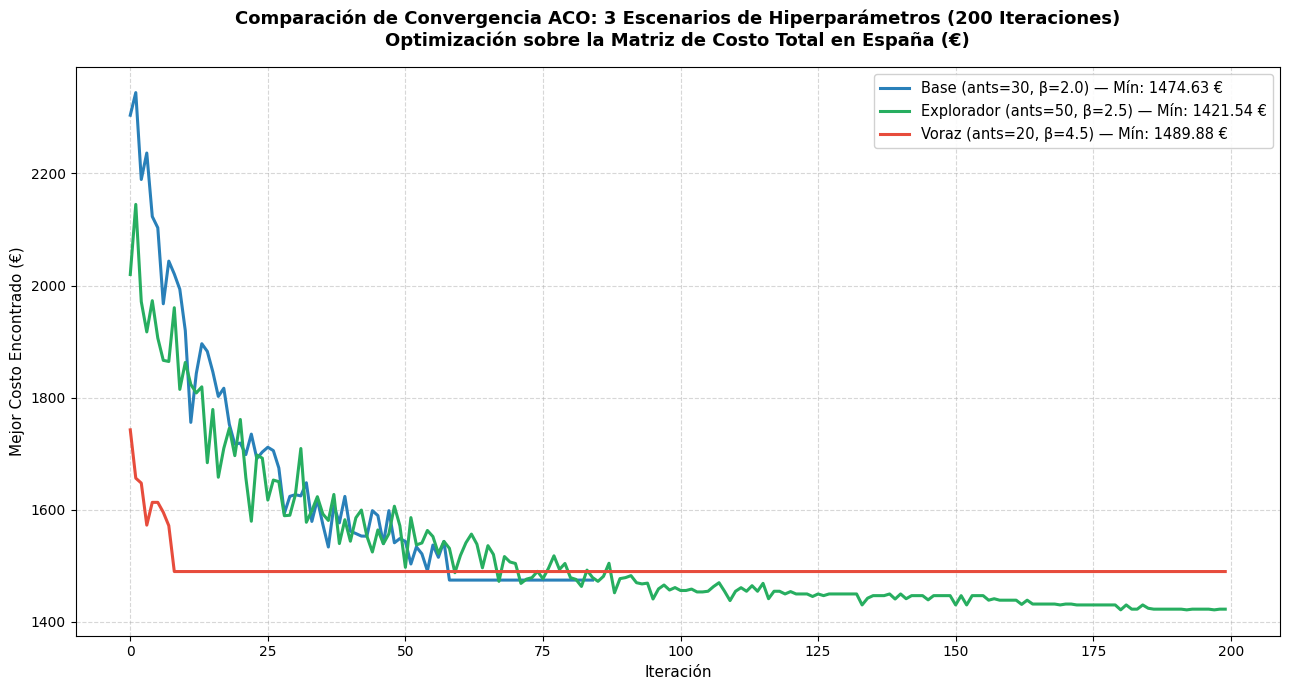

In [120]:
# Ejecutar los tres escenarios, graficar y exportar la comparación a 'Resultados imagenes/'
resultados_comparacion = comparar_escenarios_aco(
    matriz_costos=matriz_costos,
    iteraciones=200,
    carpeta_salida="Resultados_CSV_ANT",
    nombre_archivo="comparacion_hiperparametros_aco.png"
)


In [132]:
def graficar_ruta_optima_aco(
    resultado_simulacion: Any,
    df_coords: Optional[pd.DataFrame] = None,
    carpeta_salida: str = "Resultados_imagenes_ANT_OPT",
    nombre_archivo: str = "ruta_optima_aco_espana.png",
    dpi: int = 300,
    figsize: tuple = (15, 10)
) -> str:
    """
    Recibe el resultado de una simulación de ACO, extrae la mejor ruta y su costo,
    y grafica la trayectoria sobre el mapa de España con flechas direccionales,
    exportando la imagen en alta resolución.

    Parámetros:
    -----------
    resultado_simulacion : Any
        Objeto AntColonyOptimizer entrenado, o diccionario con claves 'optimizer'/'mejor_costo',
        o tupla (mejor_ruta, mejor_costo).
    df_coords : Optional[pd.DataFrame], opcional
        DataFrame con ['ciudad', 'latitud', 'longitud']. Si es None, se carga automáticamente.
    carpeta_salida : str, opcional
        Carpeta donde se guardará la imagen (por defecto 'Resultados imagenes').
    nombre_archivo : str, opcional
        Nombre del archivo PNG a generar (por defecto 'ruta_optima_aco_espana.png').
    dpi : int, opcional
        Resolución de la imagen (por defecto 300 DPI).
    figsize : tuple, opcional
        Tamaño de la figura en pulgadas (por defecto (15, 10)).

    Retorna:
    --------
    str
        Ruta completa del archivo de imagen generado.
    """
    # 1. Extraer mejor_ruta y mejor_costo según el formato de entrada
    if hasattr(resultado_simulacion, "best_path") and hasattr(resultado_simulacion, "best"):
        # Se pasó directamente el objeto optimizer
        mejor_ruta = list(resultado_simulacion.best_path)
        mejor_costo = float(resultado_simulacion.best)
    elif isinstance(resultado_simulacion, dict):
        # Se pasó un diccionario (ej. del comparador de escenarios)
        if "optimizer" in resultado_simulacion:
            opt = resultado_simulacion["optimizer"]
            mejor_ruta = list(opt.best_path)
            mejor_costo = float(opt.best)
        else:
            mejor_ruta = list(resultado_simulacion.get("mejor_ruta", []))
            mejor_costo = float(resultado_simulacion.get("mejor_costo", 0.0))
    elif isinstance(resultado_simulacion, (tuple, list)) and len(resultado_simulacion) == 2:
        mejor_ruta = list(resultado_simulacion[0])
        mejor_costo = float(resultado_simulacion[1])
    else:
        raise ValueError("Formato de resultado_simulacion no reconocido.")

    # 2. Cargar coordenadas si no fueron pasadas
    if df_coords is None:
        posibles_rutas = [
            os.path.join("Resultados_CSV_ANT", "coordenadas_capitales_espana.csv"),
            os.path.join("Parte_2", "Resultados_CSV_ANT", "coordenadas_capitales_espana.csv"),
            "coordenadas_capitales_espana.csv",
            os.path.join("Parte_2", "coordenadas_capitales_espana.csv")
        ]
        ruta_coords = next((r for r in posibles_rutas if os.path.exists(r)), None)
        if ruta_coords is None:
            raise FileNotFoundError("No se encontró el archivo 'coordenadas_capitales_espana.csv'.")
        df_coords = pd.read_csv(ruta_coords, encoding="utf-8-sig")

    lons = df_coords["longitud"].values
    lats = df_coords["latitud"].values
    nombres = df_coords["ciudad"].values

    # 3. Asegurar que el ciclo esté cerrado (vuelve al nodo de partida)
    if mejor_ruta[0] != mejor_ruta[-1]:
        mejor_ruta = mejor_ruta + [mejor_ruta[0]]

    # Coordenadas ordenadas según el itinerario
    ruta_lons = [lons[i] for i in mejor_ruta]
    ruta_lats = [lats[i] for i in mejor_ruta]

    # 4. Crear gráfico
    plt.figure(figsize=figsize)

    # Trazar el camino continuo
    plt.plot(
        ruta_lons, ruta_lats, 
        color="#2980b9", 
        linestyle="-", 
        linewidth=2.2, 
        alpha=0.85, 
        label="Trayecto Óptimo Conectado", 
        zorder=2
    )

    # Dibujar flechas direccionales en el punto medio de cada tramo
    for k in range(len(mejor_ruta) - 1):
        idx_origen = mejor_ruta[k]
        idx_destino = mejor_ruta[k + 1]
        dx = lons[idx_destino] - lons[idx_origen]
        dy = lats[idx_destino] - lats[idx_origen]
        
        plt.annotate(
            "", 
            xy=(lons[idx_origen] + 0.55 * dx, lats[idx_origen] + 0.55 * dy),
            xytext=(lons[idx_origen] + 0.45 * dx, lats[idx_origen] + 0.45 * dy),
            arrowprops=dict(arrowstyle="->", color="#1c5980", lw=1.8),
            zorder=3
        )

    # Scatter plot de todas las capitales
    plt.scatter(
        lons, lats, 
        color="#e74c3c", 
        s=90, 
        edgecolors="black", 
        linewidth=1.2, 
        label="Capitales Provinciales (47)", 
        zorder=4
    )

    # Resaltar la ciudad de inicio/fin con estrella dorada
    idx_inicio = mejor_ruta[0]
    plt.scatter(
        lons[idx_inicio], lats[idx_inicio], 
        color="#f1c40f", 
        s=230, 
        edgecolors="black", 
        linewidth=2.0, 
        marker="*", 
        label=f"Inicio / Fin ({nombres[idx_inicio]})", 
        zorder=5
    )

    # Etiquetar cada ciudad con su orden de parada
    orden_visita = {ciudad_idx: paso + 1 for paso, ciudad_idx in enumerate(mejor_ruta[:-1])}
    for idx, nombre in enumerate(nombres):
        paso_num = orden_visita.get(idx, "")
        plt.annotate(
            f"{paso_num}. {nombre}",
            (lons[idx], lats[idx]),
            textcoords="offset points",
            xytext=(5, 4),
            fontsize=8.5,
            fontweight="semibold",
            color="#2c3e50",
            zorder=6
        )

    plt.title(
        f"Ruta Óptima del Agente Viajero (Algoritmo de Hormigas - ACO)\n"
        f"Costo Económico Total Mínimo: {mejor_costo:.2f} €", 
        fontsize=14, 
        pad=15, 
        fontweight="bold"
    )
    plt.xlabel("Longitud (°)", fontsize=11)
    plt.ylabel("Latitud (°)", fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.axis("equal")
    plt.legend(loc="upper right", fontsize=10, framealpha=0.9)
    plt.tight_layout()

    # 5. Exportar a disco
    os.makedirs(carpeta_salida, exist_ok=True)
    ruta_guardado = os.path.join(carpeta_salida, nombre_archivo)
    plt.savefig(ruta_guardado, dpi=dpi, bbox_inches="tight")
    plt.show()

    print(f"ráfico de la ruta óptima guardado en: {ruta_guardado}")
    return ruta_guardado


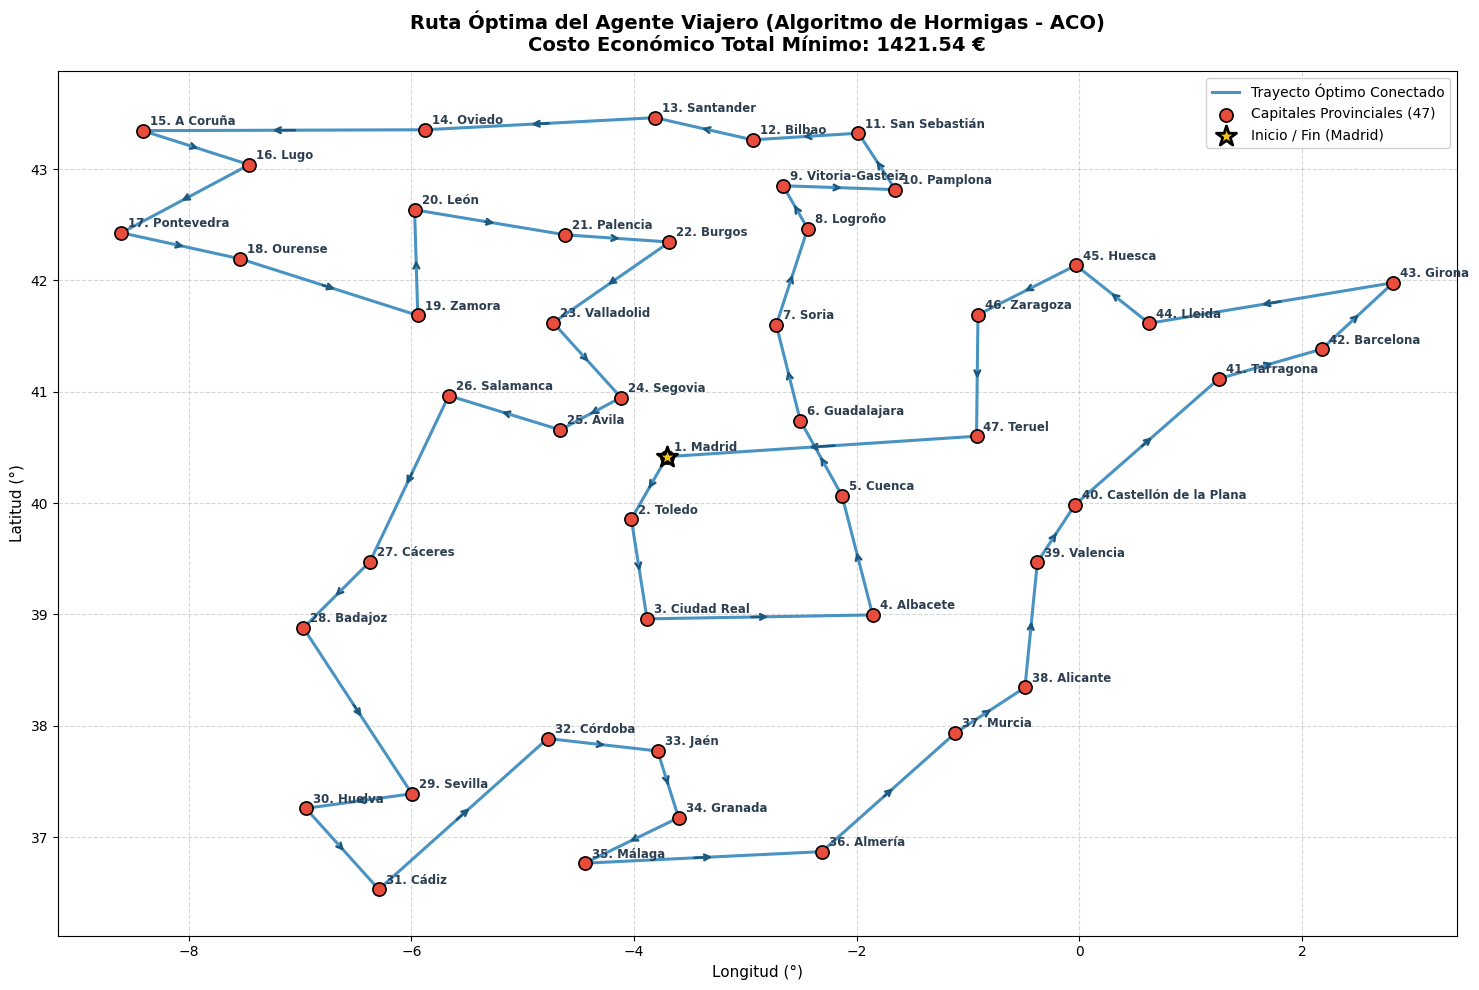

ráfico de la ruta óptima guardado en: Resultados_imagenes_ANT_OPT\ruta_optima_explorador.png


In [123]:
# Por ejemplo, graficar la mejor ruta del escenario explorador:
Tipo_analisis = "explorador" #Puede escoger entre los casos base, explorador, y voraz
ruta_guardada = graficar_ruta_optima_aco(
    resultado_simulacion=resultados_comparacion[Tipo_analisis],
    nombre_archivo=f"ruta_optima_{Tipo_analisis}.png"
)


In [133]:
def imprimir_itinerario_ruta(
    resultado_simulacion: Any,
    matriz_costos: np.ndarray,
    nombres_ciudades: List[str],
    titulo_escenario: str = "Ruta Óptima",
    guardar_csv: Optional[str] = None,
    carpeta_salida: str = "Resultados_CSV_ANT"
) -> pd.DataFrame:
    """
    Imprime en pantalla el itinerario paso a paso de una ruta del TSP mostrando 
    el costo de cada tramo y el acumulado progresivo en euros. Opcionalmente
    exporta la tabla a CSV.

    Parámetros:
    -----------
    resultado_simulacion : Any
        Objeto AntColonyOptimizer, o diccionario de resultados, o lista con los índices de la ruta.
    matriz_costos : np.ndarray
        Matriz simétrica (N x N) de costos en euros.
    nombres_ciudades : List[str]
        Lista con los nombres de las 47 ciudades en el orden de los índices.
    titulo_escenario : str, opcional
        Nombre del escenario a mostrar en el encabezado (por defecto 'Ruta Óptima').
    guardar_csv : Optional[str], opcional
        Nombre del archivo CSV si deseas exportar la tabla (ej. 'itinerario_base.csv').
    carpeta_salida : str, opcional
        Carpeta donde se guardará el CSV (por defecto 'Resultados_CSV_ANT').

    Retorna:
    --------
    pd.DataFrame
        DataFrame con las columnas ['Paso', 'Origen', 'Destino', 'Costo Tramo (€)', 'Costo Acumulado (€)'].
    """
    # 1. Extraer la lista de la ruta según el tipo de entrada
    if hasattr(resultado_simulacion, "best_path"):
        ruta = list(resultado_simulacion.best_path)
    elif isinstance(resultado_simulacion, dict):
        if "optimizer" in resultado_simulacion:
            ruta = list(resultado_simulacion["optimizer"].best_path)
        else:
            ruta = list(resultado_simulacion.get("mejor_ruta", []))
    elif isinstance(resultado_simulacion, (list, np.ndarray)):
        ruta = list(resultado_simulacion)
    else:
        raise ValueError("No se pudo extraer la ruta del resultado suministrado.")

    # Asegurar que el ciclo esté cerrado (vuelve al origen)
    if ruta[0] != ruta[-1]:
        ruta = ruta + [ruta[0]]

    # 2. Calcular los costos paso a paso y armar el itinerario
    filas = []
    costo_acumulado = 0.0

    print("=" * 82)
    print(f"  ITINERARIO DE VIAJE — {titulo_escenario.upper()}")
    print("=" * 82)
    print(f"{'Paso':<6} {'Ciudad Origen':<22} {'➔':<3} {'Ciudad Destino':<22} {'Tramo (€)':<12} {'Acumulado (€)':<14}")
    print("-" * 82)

    for paso in range(len(ruta) - 1):
        origen = ruta[paso]
        destino = ruta[paso + 1]
        costo_tramo = float(matriz_costos[origen, destino])
        costo_acumulado += costo_tramo

        nombre_origen = nombres_ciudades[origen]
        nombre_destino = nombres_ciudades[destino]

        print(f"{paso + 1:02d}     {nombre_origen:<22} ➔   {nombre_destino:<22} {costo_tramo:8.2f} €   {costo_acumulado:10.2f} €")

        filas.append({
            "Paso": paso + 1,
            "Origen": nombre_origen,
            "Destino": nombre_destino,
            "Costo Tramo (€)": round(costo_tramo, 2),
            "Costo Acumulado (€)": round(costo_acumulado, 2)
        })

    print("=" * 82)
    print(f"  COSTO TOTAL FINAL DEL CIRCUITO: {costo_acumulado:.2f} €")
    print("=" * 82)

    df_itinerario = pd.DataFrame(filas)

    # 3. Exportar a CSV si se solicita
    if guardar_csv:
        os.makedirs(carpeta_salida, exist_ok=True)
        ruta_csv = os.path.join(carpeta_salida, guardar_csv)
        df_itinerario.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
        print(f"Tabla de itinerario exportada en: {ruta_csv}")

    return df_itinerario


In [134]:
tipo_analisis = "explorador"  # Opciones: "base", "explorador", "voraz"

df_itinerario = imprimir_itinerario_ruta(
    resultado_simulacion=resultados_comparacion[tipo_analisis],
    matriz_costos=matriz_costos,
    nombres_ciudades=ciudades,
    titulo_escenario=f"Escenario {tipo_analisis.capitalize()}",
    guardar_csv=f"itinerario_{tipo_analisis}.csv"  # Se guarda en Resultados_CSV_ANT/
)


  ITINERARIO DE VIAJE — ESCENARIO EXPLORADOR
Paso   Ciudad Origen          ➔   Ciudad Destino         Tramo (€)    Acumulado (€) 
----------------------------------------------------------------------------------
01     Madrid                 ➔   Toledo                    24.74 €        24.74 €
02     Toledo                 ➔   Ciudad Real               26.93 €        51.67 €
03     Ciudad Real            ➔   Albacete                  39.50 €        91.17 €
04     Albacete               ➔   Cuenca                    32.07 €       123.24 €
05     Cuenca                 ➔   Guadalajara               32.28 €       155.52 €
06     Guadalajara            ➔   Soria                     34.26 €       189.78 €
07     Soria                  ➔   Logroño                   29.84 €       219.62 €
08     Logroño                ➔   Vitoria-Gasteiz           23.19 €       242.81 €
09     Vitoria-Gasteiz        ➔   Pamplona                  18.53 €       261.34 €
10     Pamplona               ➔   San Se

In [135]:
def generar_gif_recorrido_tsp(
    resultado_simulacion: Any,
    matriz_costos: np.ndarray,
    df_coords: Optional[pd.DataFrame] = None,
    carpeta_salida: str = "Resultados_imagenes_ANT_OPT",
    nombre_gif: str = "recorrido_optimo_tsp.gif",
    fps: int = 2,
    pausa_final_frames: int = 6,
    mostrar_en_notebook: bool = True
) -> str:
    """
    Genera un GIF animado que traza paso a paso la trayectoria del recorrido óptimo 
    del TSP en España, mostrando en tiempo real el avance y la acumulación del costo 
    en euros. Guarda el archivo en la carpeta designada y lo reproduce en el notebook.

    Parámetros:
    -----------
    resultado_simulacion : Any
        Objeto AntColonyOptimizer, diccionario de resultados o lista de índices de la ruta.
    matriz_costos : np.ndarray
        Matriz simétrica (N x N) con los costos en euros.
    df_coords : Optional[pd.DataFrame], opcional
        DataFrame con ['ciudad', 'latitud', 'longitud']. Si es None, se carga automáticamente.
    carpeta_salida : str, opcional
        Carpeta donde se guardará el GIF (por defecto 'Resultados imagenes').
    nombre_gif : str, opcional
        Nombre del archivo GIF (por defecto 'recorrido_optimo_tsp.gif').
    fps : int, opcional
        Fotogramas por segundo de la animación (por defecto 2 fps -> 500 ms por ciudad).
    pausa_final_frames : int, opcional
        Fotogramas de pausa estática al final para contemplar el tour completo (por defecto 6).
    mostrar_en_notebook : bool, opcional
        Si True, renderiza el GIF dentro de la celda de Jupyter (por defecto True).

    Retorna:
    --------
    str
        Ruta completa del archivo GIF generado.
    """
    # 1. Extraer la ruta óptima según el tipo de entrada
    if hasattr(resultado_simulacion, "best_path"):
        mejor_ruta = list(resultado_simulacion.best_path)
    elif isinstance(resultado_simulacion, dict):
        if "optimizer" in resultado_simulacion:
            mejor_ruta = list(resultado_simulacion["optimizer"].best_path)
        else:
            mejor_ruta = list(resultado_simulacion.get("mejor_ruta", []))
    elif isinstance(resultado_simulacion, (list, np.ndarray)):
        mejor_ruta = list(resultado_simulacion)
    else:
        raise ValueError("Formato de resultado_simulacion no reconocido.")

    # Asegurar el cierre del ciclo
    if mejor_ruta[0] != mejor_ruta[-1]:
        mejor_ruta = mejor_ruta + [mejor_ruta[0]]

    N_pasos = len(mejor_ruta)

    # 2. Cargar coordenadas si no se proporcionaron
    if df_coords is None:
        posibles_rutas = [
            os.path.join("Resultados_CSV_ANT", "coordenadas_capitales_espana.csv"),
            os.path.join("Parte_2", "Resultados_CSV_ANT", "coordenadas_capitales_espana.csv"),
            "coordenadas_capitales_espana.csv",
            os.path.join("Parte_2", "coordenadas_capitales_espana.csv")
        ]
        ruta_coords = next((r for r in posibles_rutas if os.path.exists(r)), None)
        if ruta_coords is None:
            raise FileNotFoundError("No se encontró 'coordenadas_capitales_espana.csv'.")
        df_coords = pd.read_csv(ruta_coords, encoding="utf-8-sig")

    lons = df_coords["longitud"].values
    lats = df_coords["latitud"].values
    ciudades = df_coords["ciudad"].values

    # 3. Precalcular costos paso a paso
    costos_tramos = [0.0]
    costos_acumulados = [0.0]

    for k in range(N_pasos - 1):
        c_origen = mejor_ruta[k]
        c_destino = mejor_ruta[k + 1]
        costo_tramo = float(matriz_costos[c_origen, c_destino])
        costos_tramos.append(costo_tramo)
        costos_acumulados.append(costos_acumulados[-1] + costo_tramo)

    # 4. Configurar la figura de Matplotlib
    fig, ax = plt.subplots(figsize=(13, 9))

    # Nodos fijos de fondo
    ax.scatter(lons, lats, color="#bdc3c7", s=70, edgecolors="black", linewidth=0.8, zorder=2)

    for i, (nombre, lat, lon) in enumerate(zip(ciudades, lats, lons)):
        ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(4, 4), 
                    fontsize=7.5, color="#7f8c8d", alpha=0.85, zorder=3)

    # Ciudad de inicio destacada
    inicio_idx = mejor_ruta[0]
    ax.scatter(lons[inicio_idx], lats[inicio_idx], color="#f1c40f", s=190, 
               edgecolors="black", marker="*", zorder=6, label=f"Inicio/Fin: {ciudades[inicio_idx]}")

    # Elementos dinámicos actualizables
    linea_ruta, = ax.plot([], [], color="#2980b9", lw=2.2, alpha=0.85, zorder=4)
    punto_actual, = ax.plot([], [], marker="o", color="#e74c3c", markersize=12, 
                            markeredgecolor="black", markeredgewidth=1.5, zorder=7)
    puntos_visitados, = ax.plot([], [], marker="o", color="#27ae60", markersize=8, 
                                linestyle="", markeredgecolor="black", zorder=5)

    # Panel informativo flotante
    caja_info = ax.text(
        0.03, 0.95, "", transform=ax.transAxes, fontsize=10.5, verticalalignment="top",
        fontfamily="monospace",
        bbox=dict(boxstyle="round,pad=0.6", facecolor="#ffffff", edgecolor="#34495e", lw=1.5, alpha=0.92),
        zorder=10
    )

    ax.set_title("Animación Dinámica del Recorrido Óptimo (ACO - TSP en España)", fontsize=13, pad=12, fontweight="bold")
    ax.set_xlabel("Longitud (°)", fontsize=11)
    ax.set_ylabel("Latitud (°)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.axis("equal")
    ax.legend(loc="lower right", fontsize=9.5)
    plt.tight_layout()

    # 5. Función de actualización frame a frame
    def actualizar(frame):
        sub_indices = mejor_ruta[:frame + 1]
        sub_lons = [lons[idx] for idx in sub_indices]
        sub_lats = [lats[idx] for idx in sub_indices]
        
        linea_ruta.set_data(sub_lons, sub_lats)
        puntos_visitados.set_data(sub_lons[:-1], sub_lats[:-1])
        
        nodo_actual = mejor_ruta[frame]
        punto_actual.set_data([lons[nodo_actual]], [lats[nodo_actual]])
        
        nombre_actual = ciudades[nodo_actual]
        costo_tramo = costos_tramos[frame]
        acumulado = costos_acumulados[frame]
        
        if frame == 0:
            tramo_str = "Punto de Partida"
        elif frame == N_pasos - 1:
            tramo_str = f"Retorno al inicio (+{costo_tramo:.2f} €)"
        else:
            tramo_str = f"Tramo: +{costo_tramo:.2f} €"

        progreso = (frame / (N_pasos - 1)) * 100
        
        texto = (
            f"📍 Paso: {frame}/{N_pasos - 1}\n"
            f"🏙️ Ciudad: {nombre_actual}\n"
            f"💶 {tramo_str}\n"
            f"-----------------------------\n"
            f"💰 Costo Total: {acumulado:7.2f} €\n"
            f"📊 Progreso:    [{progreso:5.1f}%]"
        )
        caja_info.set_text(texto)
        return linea_ruta, punto_actual, puntos_visitados, caja_info

    # 6. Renderizar y guardar el GIF
    print(f"⏳ Renderizando GIF animado: '{nombre_gif}'...")
    frames_totales = list(range(N_pasos)) + [N_pasos - 1] * pausa_final_frames

    anim = animation.FuncAnimation(
        fig, 
        actualizar, 
        frames=frames_totales, 
        interval=int(1000 / fps), 
        blit=True
    )

    os.makedirs(carpeta_salida, exist_ok=True)
    ruta_guardado = os.path.join(carpeta_salida, nombre_gif)
    anim.save(ruta_guardado, writer=animation.PillowWriter(fps=fps))
    plt.close(fig)

    print(f"✅ ¡GIF guardado exitosamente en: {ruta_guardado}!")

    # 7. Visualizar directamente en Jupyter
    if mostrar_en_notebook:
        display(Image(filename=ruta_guardado))

    return ruta_guardado


⏳ Renderizando GIF animado: 'recorrido_optimo_explorador.gif'...
✅ ¡GIF guardado exitosamente en: Resultados_imagenes_ANT_OPT\recorrido_optimo_explorador.gif!


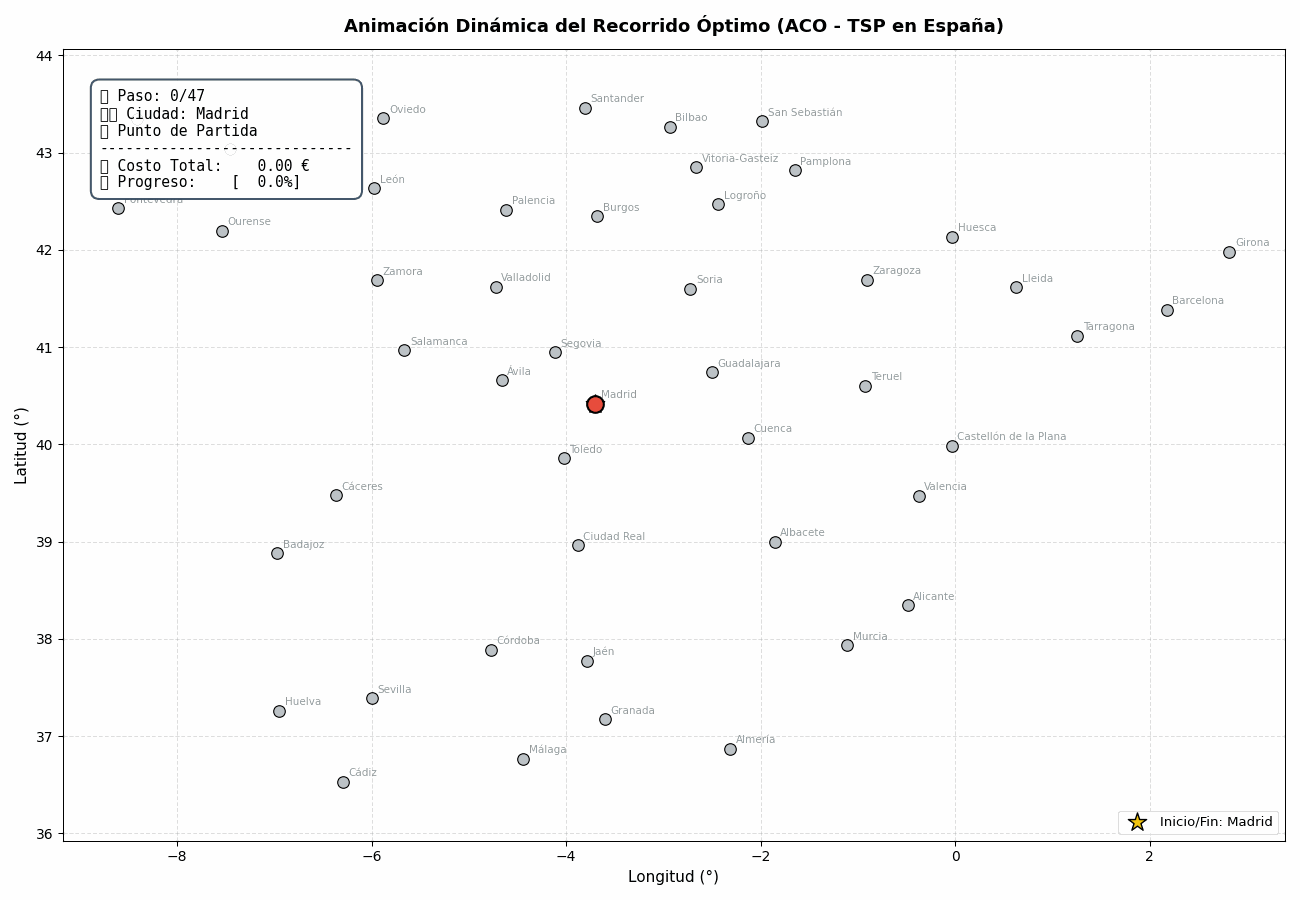

In [136]:
tipo_analisis = "explorador"  # Opciones: "base", "explorador", "voraz"

ruta_gif = generar_gif_recorrido_tsp(
    resultado_simulacion=resultados_comparacion[tipo_analisis],
    matriz_costos=matriz_costos,
    carpeta_salida="Resultados_imagenes_ANT_OPT",
    nombre_gif=f"recorrido_optimo_{tipo_analisis}.gif",
    fps=2  # 2 pasos por segundo
)


⏳ Renderizando animación de la ruta óptima...
✅ ¡GIF generado exitosamente con el nombre: 'recorrido_optimo_tsp.gif'!


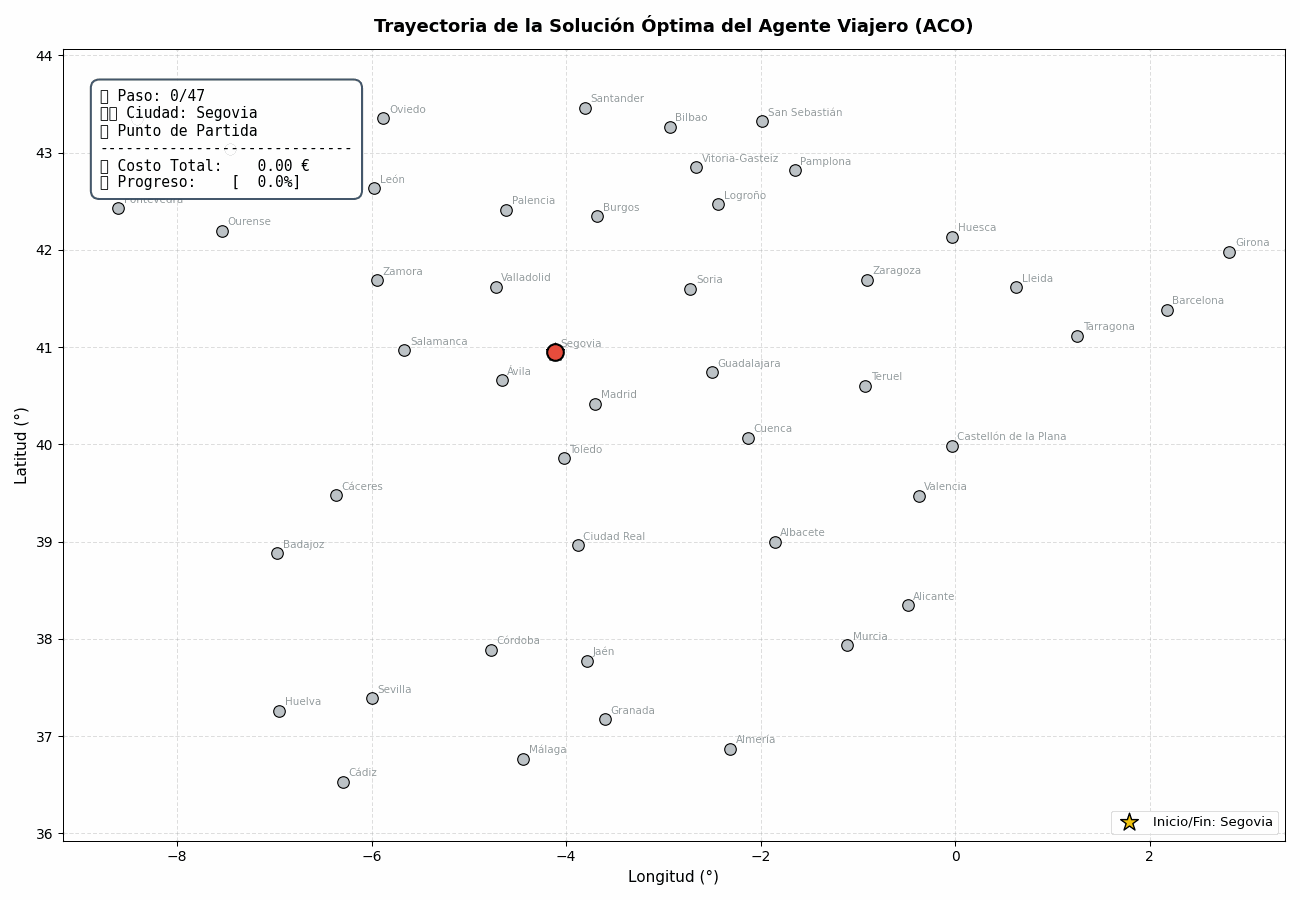

In [58]:
# 1. Cargar coordenadas y matriz de costos
ruta_coords = "coordenadas_capitales_espana.csv" if os.path.exists("coordenadas_capitales_espana.csv") else "Parte_2/coordenadas_capitales_espana.csv"
df_coords = pd.read_csv(ruta_coords)

lons = df_coords["longitud"].values
lats = df_coords["latitud"].values
ciudades = df_coords["ciudad"].values

# 2. Obtener la mejor ruta (cerrando el ciclo)
mejor_ruta = optimizer.best_path
if mejor_ruta[0] != mejor_ruta[-1]:
    mejor_ruta = list(mejor_ruta) + [mejor_ruta[0]]

N_pasos = len(mejor_ruta)  # 48 puntos (47 ciudades + regreso al origen)

# 3. Precalcular los costos acumulados paso a paso
costos_tramos = [0.0]
costos_acumulados = [0.0]

for k in range(N_pasos - 1):
    c_origen = mejor_ruta[k]
    c_destino = mejor_ruta[k + 1]
    costo_tramo = matriz_costos[c_origen, c_destino]
    costos_tramos.append(costo_tramo)
    costos_acumulados.append(costos_acumulados[-1] + costo_tramo)

# 4. Configurar la figura de Matplotlib
fig, ax = plt.subplots(figsize=(13, 9))

# Fondo: Nodos fijos de las 47 ciudades
ax.scatter(lons, lats, color="#bdc3c7", s=70, edgecolors="black", linewidth=0.8, zorder=2)

for i, (nombre, lat, lon) in enumerate(zip(ciudades, lats, lons)):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(4, 4), 
                fontsize=7.5, color="#7f8c8d", alpha=0.85, zorder=3)

# Resaltar la ciudad de inicio/fin con una estrella dorada
inicio_idx = mejor_ruta[0]
ax.scatter(lons[inicio_idx], lats[inicio_idx], color="#f1c40f", s=180, 
           edgecolors="black", marker="*", zorder=6, label=f"Inicio/Fin: {ciudades[inicio_idx]}")

# Elementos dinámicos que se actualizarán en cada frame del GIF:
# - Línea del trayecto recorrido
linea_ruta, = ax.plot([], [], color="#2980b9", lw=2.2, alpha=0.85, zorder=4)
# - Marcador móvil de la posición actual del viajero
punto_actual, = ax.plot([], [], marker="o", color="#e74c3c", markersize=12, 
                        markeredgecolor="black", markeredgewidth=1.5, zorder=7)
# - Puntos visitados que se iluminan
puntos_visitados, = ax.plot([], [], marker="o", color="#27ae60", markersize=8, 
                            linestyle="", markeredgecolor="black", zorder=5)

# Panel de información en pantalla (Marcador de costos)
caja_info = ax.text(
    0.03, 0.95, "", transform=ax.transAxes, fontsize=10.5, verticalalignment="top",
    fontfamily="monospace",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#ffffff", edgecolor="#34495e", lw=1.5, alpha=0.92),
    zorder=10
)

ax.set_title("Trayectoria de la Solución Óptima del Agente Viajero (ACO)", fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Longitud (°)", fontsize=11)
ax.set_ylabel("Latitud (°)", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
ax.axis("equal")
ax.legend(loc="lower right", fontsize=9.5)
plt.tight_layout()

# 5. Función de actualización para cada fotograma (frame)
def actualizar(frame):
    # Sub-ruta recorrida hasta este fotograma
    sub_indices = mejor_ruta[:frame + 1]
    sub_lons = [lons[idx] for idx in sub_indices]
    sub_lats = [lats[idx] for idx in sub_indices]
    
    # Actualizar la línea y los puntos
    linea_ruta.set_data(sub_lons, sub_lats)
    puntos_visitados.set_data(sub_lons[:-1], sub_lats[:-1])
    
    # Posición actual del viajero
    nodo_actual = mejor_ruta[frame]
    punto_actual.set_data([lons[nodo_actual]], [lats[nodo_actual]])
    
    # Texto del marcador dinámico
    nombre_actual = ciudades[nodo_actual]
    costo_tramo = costos_tramos[frame]
    acumulado = costos_acumulados[frame]
    
    if frame == 0:
        tramo_str = "Punto de Partida"
    elif frame == N_pasos - 1:
        tramo_str = f"Regreso al inicio (+{costo_tramo:.2f} €)"
    else:
        tramo_str = f"Tramo: +{costo_tramo:.2f} €"

    progreso = (frame / (N_pasos - 1)) * 100
    
    texto = (
        f"📍 Paso: {frame}/{N_pasos - 1}\n"
        f"🏙️ Ciudad: {nombre_actual}\n"
        f"💶 {tramo_str}\n"
        f"-----------------------------\n"
        f"💰 Costo Total: {acumulado:7.2f} €\n"
        f"📊 Progreso:    [{progreso:5.1f}%]"
    )
    caja_info.set_text(texto)
    
    return linea_ruta, punto_actual, puntos_visitados, caja_info

# 6. Compilar la animación y guardarla como GIF (2 fotogramas por segundo)
print("⏳ Renderizando animación de la ruta óptima...")
# Añadimos 6 fotogramas adicionales al final para pausar la vista en el resultado completo
frames_con_pausa = list(range(N_pasos)) + [N_pasos - 1] * 6

anim = animation.FuncAnimation(
    fig, 
    actualizar, 
    frames=frames_con_pausa, 
    interval=500,     # 500 ms por paso (2 ciudades por segundo)
    blit=True
)

nombre_gif = "recorrido_optimo_tsp.gif"
anim.save(nombre_gif, writer=animation.PillowWriter(fps=2))
plt.close(fig)  # Cerrar la figura estática

print(f"✅ ¡GIF generado exitosamente con el nombre: '{nombre_gif}'!")

# 7. Mostrar el GIF directamente en el notebook
display(Image(filename=nombre_gif))


In [137]:
class AntColonyOptimizerConHistorial(AntColonyOptimizer):
    """
    Extensión de AntColonyOptimizer que almacena la mejor ruta encontrada
    en cada iteración para poder exportar la evolución a gif_ruta.py.
    """
    def fit(self, map_matrix, iterations=100, mode='min', early_stopping_count=20, verbose=True):
        if verbose: 
            print(f"Iniciando ACO con {iterations} iteraciones y registro histórico...")
        self.map = map_matrix
        start = time.time()
        self._initialize()
        num_equal = 0
        
        # Historial de mejores rutas por iteración
        self.best_path_history = []

        for i in range(iterations):
            start_iter = time.time()
            paths = []
            path = []

            for ant in range(self.ants):
                current_node = self.set_of_available_nodes[np.random.randint(0, len(self.set_of_available_nodes))]
                start_node = current_node
                while True:
                    path.append(current_node)
                    self._remove_node(current_node)
                    if len(self.set_of_available_nodes) != 0:
                        current_node_index = self._choose_next_node(current_node)
                        current_node = self.set_of_available_nodes[current_node_index]
                    else:
                        break

                path.append(start_node)  # Cierre del ciclo
                self._reinstate_nodes()
                paths.append(path)
                path = []

            best_path_coords, best_path, best_score = self._evaluate(paths, mode)

            if i == 0:
                best_score_so_far = best_score
                self.best_path = best_path
            else:
                if mode == 'min':
                    if best_score < best_score_so_far:
                        best_score_so_far = best_score
                        self.best_path = best_path
                elif mode == 'max':
                    if best_score > best_score_so_far:
                        best_score_so_far = best_score
                        self.best_path = best_path

            # Guardar la mejor ruta de esta iteración (sin el nodo repetido al final)
            ruta_sin_cierre = list(self.best_path[:-1] if self.best_path[0] == self.best_path[-1] else self.best_path)
            self.best_path_history.append(ruta_sin_cierre)

            if best_score == best_score_so_far:
                num_equal += 1
            else:
                num_equal = 0

            self.best_series.append(best_score_so_far)
            self._evaporation()
            self._intensify(best_path_coords)
            self._update_probabilities()

            if verbose: 
                print(f"Iteración {i:03d} | Mejor iter: {best_score:,.2f} € | Global: {best_score_so_far:,.2f} € ({round(time.time() - start_iter)}s)")

            if best_score == best_score_so_far and num_equal == early_stopping_count:
                self.stopped_early = True
                print(f"Parada temprana alcanzada tras {early_stopping_count} iteraciones sin mejora.")
                break

        self.fit_time = round(time.time() - start)
        self.fitted = True

        if mode == 'min':
            self.best = self.best_series[-1]
            if verbose: 
                print(f"ACO finalizado en {self.fit_time // 60}m {self.fit_time % 60}s. Mejor costo: {self.best:,.2f} €")
            return self.best
        elif mode == 'max':
            self.best = self.best_series[-1]
            return self.best
        else:
            raise ValueError("Modo no válido. Usa 'min' o 'max'.")


In [138]:
def exportar_rutas_por_generacion_aco(
    optimizer_con_historial: AntColonyOptimizerConHistorial,
    ciudades: List[str],
    nombre_archivo: str = "rutas_por_generacion_aco.csv",
    carpeta: str = "Resultados_CSV_ANT"
) -> str:
    """
    Genera el archivo CSV con las columnas ('generacion', 'costo_eur', 'ruta')
    requeridas por gif_ruta.py para trazar la animación.
    """
    os.makedirs(carpeta, exist_ok=True)
    ruta_csv = os.path.join(carpeta, nombre_archivo)
    
    registros = []
    for gen, (costo, ruta_indices) in enumerate(zip(optimizer_con_historial.best_series, optimizer_con_historial.best_path_history)):
        # Convertir índices a nombres de ciudades separados por ' | '
        ruta_ciudades = " | ".join([ciudades[idx] for idx in ruta_indices])
        registros.append({
            "generacion": gen,
            "costo_eur": round(costo, 2),
            "ruta": ruta_ciudades
        })
        
    df_rutas = pd.DataFrame(registros)
    df_rutas.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
    print(f"✅ CSV de rutas por generación guardado: '{ruta_csv}' ({len(df_rutas)} filas)")
    return ruta_csv


In [ ]:
def crear_gif_evolucion_aco(
    ruta_csv_rutas: str = "Resultados_CSV_ANT/rutas_por_generacion_aco.csv",
    ruta_coords: str = "coordenadas_capitales.csv",
    carpeta_salida: str = "Resultados imagenes",
    titulo: str = "Colonia de Hormigas (ACO)",
    max_cuadros: int = 60,
    fps: float = 5.0,
    pausa_final: int = 8
) -> str:
    """
    Ejecuta el script gif_ruta.py mediante subproceso con los parámetros del experimento
    y muestra el GIF generado resultante.
    """
    script_path = "gif_ruta.py" if os.path.exists("gif_ruta.py") else os.path.join("Parte_2", "gif_ruta.py")
    
    comando = [
        sys.executable, script_path,
        "--rutas", ruta_csv_rutas,
        "--coordenadas", ruta_coords,
        "--salida", carpeta_salida,
        "--titulo", titulo,
        "--max-cuadros", str(max_cuadros),
        "--fps", str(fps),
        "--pausa-final", str(pausa_final)
    ]
    
    print(f"🎬 Generando GIF con {script_path}...")
    resultado = subprocess.run(comando, capture_output=True, text=True, check=True)
    print(resultado.stdout)
    
    archivo_gif = os.path.join(carpeta_salida, "evolucion_ruta.gif")
    if os.path.exists(archivo_gif):
        print(f"¡Animación generada en: '{archivo_gif}'!")
        display(Image(filename=archivo_gif))
    return archivo_gif


Iniciando ACO con 200 iteraciones y registro histórico...
Iteración 000 | Mejor iter: 2,258.47 € | Global: 2,258.47 € (0s)
Iteración 001 | Mejor iter: 2,098.24 € | Global: 2,098.24 € (0s)
Iteración 002 | Mejor iter: 1,883.89 € | Global: 1,883.89 € (0s)
Iteración 003 | Mejor iter: 2,030.90 € | Global: 1,883.89 € (0s)
Iteración 004 | Mejor iter: 1,985.89 € | Global: 1,883.89 € (0s)
Iteración 005 | Mejor iter: 1,898.72 € | Global: 1,883.89 € (0s)
Iteración 006 | Mejor iter: 1,879.84 € | Global: 1,879.84 € (0s)
Iteración 007 | Mejor iter: 1,767.53 € | Global: 1,767.53 € (0s)
Iteración 008 | Mejor iter: 1,822.64 € | Global: 1,767.53 € (0s)
Iteración 009 | Mejor iter: 1,857.69 € | Global: 1,767.53 € (0s)
Iteración 010 | Mejor iter: 1,842.80 € | Global: 1,767.53 € (0s)
Iteración 011 | Mejor iter: 1,855.38 € | Global: 1,767.53 € (0s)
Iteración 012 | Mejor iter: 1,785.72 € | Global: 1,767.53 € (0s)
Iteración 013 | Mejor iter: 1,814.14 € | Global: 1,767.53 € (0s)
Iteración 014 | Mejor iter: 1,80

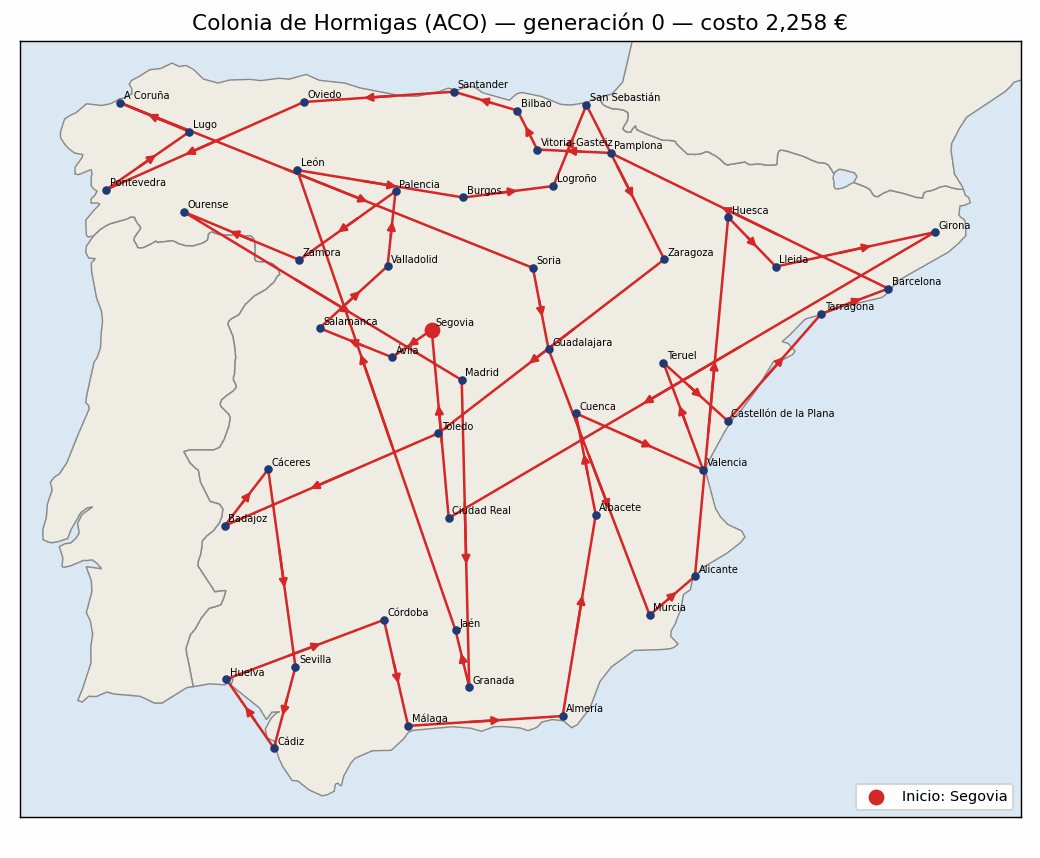

'Resultados_imagenes_ANT_OPT\\evolucion_ruta.gif'

In [ ]:
# 1. Instanciar y ejecutar el optimizador con registro histórico
opt_gif = AntColonyOptimizerConHistorial(
    ants=50, 
    evaporation_rate=0.05, 
    intensification=1.5, 
    alpha=1.0, 
    beta=2.5, 
    choose_best=0.05  
    )
opt_gif.fit(matriz_costos, iterations=200, verbose=True)

# 2. Exportar el CSV con el formato que lee gif_ruta.py
csv_rutas = exportar_rutas_por_generacion_aco(
    optimizer_con_historial=opt_gif,
    ciudades=ciudades,
    nombre_archivo="rutas_por_generacion_aco.csv",
    carpeta="Resultados_CSV_ANT"
)

# 3. Invocar gif_ruta.py y desplegar el GIF
crear_gif_evolucion_aco(
    ruta_csv_rutas=csv_rutas,
    ruta_coords="coordenadas_capitales.csv",
    carpeta_salida="Resultados_imagenes_ANT_OPT",
    titulo="Colonia de Hormigas (ACO)",
    fps=5,
    max_cuadros=50
)
